# Pilot Jev run: analysis for the paper

**Study:** Implication-Weighted Data Selection for Financial QA — Protocol v1 (training-free).
**Run analysed:** the pilot scoring of 299 pool items with TypeSafe Jev (`jev-1.14.0`) on 24 October 2026, produced by `python -m fqsel run jev profile=pilot`.

This notebook documents everything the paper needs to know about the pilot Jev run:

- the sample;
- the measurement procedure and its cost;
- the reliability of the Jev probabilities;
- the distributions of the constructs R and I;
- and what the pilot already says about the hypotheses and decision gates of the protocol.

**What a pilot can and cannot claim.** The protocol's validity analyses (E0, Spec 3) and gates D1–D4 are computed on the full pool: about 19,000 originals and 1,000 negatives. The pilot has 200 originals and 99 original/negative pairs. Every gate quantity below is therefore a **preview with a confidence interval, not a gate decision**.

The pilot serves three purposes:
1. to check that the measurement works end to end on the real API;
2. to fix the measurement decisions that Spec 1 makes on a pilot (determinism and batching);
3. to estimate effect sizes, cost and cell sizes for the full run.

**No API calls are made here.** Per-repeat and single-question probabilities are read from the client's on-disk response cache. The cache keys are rebuilt exactly as the `jev` stage builds them, and the notebook fails if any response is missing.

## 0. The thesis and where the pilot fits

The thesis decomposes the value of a training example into three quantities:

- **reliability R**: P(datum is true), from Jev Q1;
- **implication strength I**: P(task-relevant consequence | datum is true), the mean of Jev Q2 (determinacy) and Q3 (consequence);
- **surprisal S**: how far the datum would move the base model.

The central claim is a moderation: I determines whether surprising data is useful (H4). R is a gate, not the driver.

The pilot measures **R and I only**. S, the value proxies G and C, and the comparators (base-model accuracy, PVI, ICL-reducible loss, judge quality, self-consistency) come from later milestones.

| Protocol element | What the pilot can show |
|---|---|
| **H1** (E0): Jev scores are valid and new | AUROC of R against correctness (A1): **preview**. The correlations with base-model accuracy, PVI and ICL-reducible loss need Spec 2 and Spec 3: **not yet** |
| **D1**, validity on arithmetic items | AUROC of R on `arith` pairs: **preview** |
| **D2**, I as a difficulty proxy | Needs base-model accuracy (M4): **not yet**. Context length is shown as a weak stand-in |
| **D3**, separability of R and I | ρ(R, I) on originals: **preview** |
| **D4**, cell sizes | Share of items with R ≥ 0.9, extrapolated to the full pool: **projection** |
| **E0** test-retest between batteries | Original versus paraphrased battery: **preview** |
| **H2–H6**, E1–E3 | Need S, G and C: **not addressed**. The pilot only shows whether R and I have the spread these tests need |
| Measurement decisions (Spec 1) | Determinism and batching checks: **final for the pilot**. The full run repeats them |

### Headline findings

These come from the outputs below. Section 13 has the full table.

1. **The measurement works and is cheap.** There were 2,097 requests in about 30 seconds with no errors. Every response reported `jev-1.14.0`. Batching all six questions per item cuts input tokens by 81% and changes no answer systematically.
2. **Repeated calls are not identical, but are very reliable.** Identical requests differ by 0.016 on average, within the determinism tolerance of 0.017, so each item is scored once. Single-call reliability is ICC ≈ 0.99. The tolerance was raised from 0.01 after the pilot (owner decision, 24 October 2026); under 0.01 the pilot was first scored in triplicate.
3. **R tracks correctness strongly (H1 preview).** On the 99 paired constructed negatives, AUROC = 0.95 [0.91, 0.97]; on arithmetic items it is 0.91 [0.85, 0.95], far above D1's 0.70. The hardest errors are sign flips and subtle numeric factors.
4. **R and I are only moderately separable (D3 preview), and Q2 is the reason.** ρ(R, I) = 0.73 [0.65, 0.79], just below the 0.8 threshold; in FinQA the interval crosses it. Q2 (determinacy) correlates 0.87 with Q1 (support) and drops almost as much as Q1 on wrong answers. Q3 (consequence) behaves as the thesis intends: it is nearly independent of Q1 and drops much less. **This is the main risk the pilot surfaces for the full run.**
5. **Scores are robust to paraphrase:** ρ = 0.95 for R and 0.96 for I.
6. **Cells will be large enough (D4 projection).** 54% (FinQA) and 82% (TAT-QA) of originals have R ≥ 0.9, which projects to hundreds of items per cell.

## 1. Setup and provenance

In [1]:
import json
import math
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import roc_auc_score

from fqsel.clients.cache import JsonCache, cache_key
from fqsel.clients.jev import canonical_questions
from fqsel.config import CODE_DIR, cache_dir, config_hash, load_config
from fqsel.ids import rng
from fqsel.io import read_table
from fqsel.prompts import render_item
from fqsel.stages import get_stage
from fqsel.stages.jev import QIDS, QUESTIONS, build_questions, load_battery

cfg = load_config(["profile=pilot"], ignore=get_stage("jev").ignores)
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 2000
SEED = int(cfg.global_seed)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

manifest = json.loads((CODE_DIR / "results" / "jev_manifest.json").read_text())
print("profile:", cfg.profile, "| config hash:", config_hash(cfg)[:12])
print("Jev model pinned:", cfg.jev.model, "| reported:", manifest["jev_model_version"])
print("battery version:", cfg.jev.battery_version, "| question type:", cfg.jev.question_type)
print("model.base:", cfg.model.base.name, "| model.strong (Q3 fallback):", cfg.model.strong.version)

profile: pilot | config hash: 5035786ebc7b
Jev model pinned: jev-1.14.0 | reported: jev-1.14.0
battery version: v0 | question type: noul
model.base: allenai/Olmo-3-7B-Instruct | model.strong (Q3 fallback): Qwen/Qwen3-235B-A22B-Instruct-2507


In [2]:
pool = read_table("pool", cfg)
verified = read_table("verified", cfg)[["item_id", "verified", "failure_reason"]]
checks = read_table("q3_checks", cfg)
long = pd.read_parquet(CODE_DIR / "scores" / "jev_scores_long.parquet")
scores = pd.read_parquet(CODE_DIR / "scores" / "jev_scores.parquet")

items = (pool[pool["split"] == "pool"].merge(verified, on="item_id")
         .merge(checks[["item_id", "check_text", "check_type", "source"]], on="item_id", how="left"))
items["base_id"] = np.where(items["is_derived"], items["base_item_id"], items["item_id"])
df = scores.merge(items, on="item_id", validate="one_to_one")
orig = df[~df["is_negative"]].copy()
neg = df[df["is_negative"]].copy()
pairs = orig.merge(neg, left_on="item_id", right_on="base_id", suffixes=("", "_neg"))
print(f"pool targets: {len(items)}; scored: {len(df)} (originals {len(orig)}, negatives {len(neg)}); "
      f"original/negative pairs: {len(pairs)}")
print("without a Q3 check (not scored):", sorted(set(items["item_id"]) - set(df["item_id"])))

pool targets: 300; scored: 299 (originals 200, negatives 99); original/negative pairs: 99
without a Q3 check (not scored): ['tatqa:ab239b18-a31d-4317-a3fc-309e4d7f08c7#neg']


## 2. The pilot sample

The pilot pool has 100 items per dataset, drawn from the deduplicated, leakage-filtered training splits. Each dataset is stratified by `answer_type` in proportion to its training composition. The 100 validation negatives are pool items with a wrong gold answer, stratified by dataset × `answer_type` (Spec 1; the full run uses 1,000).

One negative was dropped because its Q3 check could not be generated, so its original has no pair.

In [3]:
comp = (df.assign(kind=np.where(df["is_negative"], "negative", "original"))
          .pivot_table(index=["dataset", "answer_type"], columns="kind", values="item_id", aggfunc="count",
                       fill_value=0))
comp.loc[("total", ""), :] = comp.sum()
display(comp.astype(int))
display(neg["perturbation"].str.replace(r":.*", "", regex=True).value_counts().rename("negatives by perturbation").to_frame())

kind                 negative  original
dataset answer_type                    
finqa   arith              49        97
        lookup              1         3
tatqa   arith              22        44
        lookup             27        56
total                      99       200

,negatives by perturbation
perturbation,
factor,69
sign_flip,16
span_swap,14


**Verified correctness.** Every original passes execution-based verification: the FinQA program is re-executed, or the TAT-QA derivation is re-evaluated. So the pilot has no naturally false labels, and A1 must rely on constructed negatives, as Spec 1 anticipated.

The table below shows that 14 negatives also "verify". All are TAT-QA span swaps: span verification only checks that the answer appears in the context, and a swapped span comes from the same context. Their labels are still wrong with respect to the gold answer. **For the paper:** span verification is a necessary condition, not a sufficient one.

In [4]:
display(df.groupby(["is_negative", "answer_type"])["verified"].value_counts(dropna=False).unstack(fill_value=0))
display(neg[neg["verified"] == True][["item_id", "source_answer_type", "perturbation"]]
        .groupby(["source_answer_type", "perturbation"]).size().rename("verified negatives").to_frame())

verified                 False  True 
is_negative answer_type              
False       arith            0    141
            lookup           0     59
True        arith           71      0
            lookup          14     14

,,verified negatives
source_answer_type,perturbation,
multi-span,span_swap,6
span,span_swap,8


**Q3 checks.** Each item has one check statement that must hold whenever the stated answer holds. Checks come from templates over the gold program or derivation where possible, and from Qwen3-235B otherwise. Negatives get a check regenerated from their *wrong* answer.

The checks have **not yet been human-validated**. Spec 1 requires that both annotators accept at least 90% of a sample, and the CSVs are with the annotators. Everything that depends on Q3 (Q3, Q3′, and therefore I and I′) is provisional until then. R does not depend on the checks.

In [5]:
display(pd.crosstab([df["is_negative"], df["source"]], df["check_type"], margins=True))

check_type            direction  magnitude  ordering  total  unit  All
is_negative source                                                    
False       llm              19          5        23     11     0   58
            template         25          5       100     12     0  142
True        llm               6          4        14      3     1   28
            template         16          2        46      7     0   71
All                          66         16       183     33     1  299

## 3. Measurement procedure and cost

The procedure follows Spec 1:

- **State:** each item is rendered once as the `judge` view (table, context, question and stated answer).
- **Questions:** all six noul questions go in **one batched request**: Q1–Q3 and their paraphrases Q1′–Q3′.
- **Determinism check:** 200 items are scored twice.
- **Batching check:** the same 200 items are also scored one question per request.
- **Scoring:** the full run follows the outcome of both checks.

Request counts below come from the client's call log, which records every request actually sent; cache hits are excluded. The manifest's `full_run` counts include the preflight responses that the full run reused from the cache.

In [6]:
calls = pd.read_json(CODE_DIR / ".cache" / "logs" / "jev_calls.jsonl", lines=True)
calls = calls[calls["model"] == cfg.jev.model]
calls["at"] = pd.to_datetime(calls["at"])
judgments = int(calls["n_questions"].sum())
cost_tbl = calls.groupby("n_questions").agg(requests=("key", "size"), input_tokens=("input_tokens", "sum"),
                                            mean_tokens=("input_tokens", "mean"))
cost_tbl.index = cost_tbl.index.map({1: "single-question (batching check)", 6: "batched, 6 questions"})
cost_tbl.loc["total"] = [len(calls), calls["input_tokens"].sum(), calls["input_tokens"].mean()]
display(cost_tbl.astype({"requests": int, "input_tokens": int}))
wall = (calls["at"].max() - calls["at"].min()).total_seconds()
print(f"requests sent: {len(calls)}; judgments (question answers): {judgments}; "
      f"wall-clock time: {wall:.0f} s with {cfg.jev.max_workers} parallel workers; "
      f"distinct request IDs: {calls['request_id'].nunique()}; errors needing retries: none logged")

,requests,input_tokens,mean_tokens
n_questions,,,
single-question (batching check),1200,1359756,1133.130
"batched, 6 questions",897,1148154,1279.993
total,2097,2507910,1195.951


requests sent: 2097; judgments (question answers): 6582; wall-clock time: 30 s with 8 parallel workers; distinct request IDs: 2097; errors needing retries: none logged


**Findings.** The run sent 2,097 requests (2.51M input tokens) in about 30 seconds, with no retries and a distinct request ID for every call.

A batched request averages about 1,280 input tokens. A single-question request averages about 1,130, so most of a request's cost is the state, not the question.

**Saving from batching.** For the 200 batching-check items there are two costs to compare: six single-question requests, or one batched request carrying all six questions. The difference is what Spec 1's batching change saves.

In [7]:
battery = load_battery("v0")  # the pilot was scored with battery v0
check_of = checks.set_index("item_id")["check_text"].to_dict()
item_rows = items.set_index("item_id")
states = {i: render_item(item_rows.loc[i], "judge") for i in df["item_id"]}
questions = {i: build_questions(battery, check_of[i]) for i in df["item_id"]}
cache = JsonCache(cache_dir(cfg) / "jev")


def cached(state, qs, repeat=0):
    # the jev stage's cache key: (model, state, canonical questions[, repeat])
    parts = [cfg.jev.model, state, canonical_questions(qs)] + ([repeat] if repeat else [])
    hit = cache.get(cache_key(*parts))
    if hit is None:
        raise KeyError("response missing from the cache; this notebook never calls the API")
    return hit


pre_ids = manifest["item_ids"]
assert len(pre_ids) == manifest["n_items"] == 200
rows = []
for i in df["item_id"]:
    for r in range(int(cfg.jev.determinism.repeats)):
        resp = cached(states[i], questions[i], r)
        rows += [{"item_id": i, "mode": "batched", "repeat": r, "qid": q, "p": p,
                  "tokens": resp["input_tokens"]} for q, p in resp["probs"].items()]
    if i in pre_ids:
        for q, text in questions[i].items():
            resp = cached(states[i], {q: text})
            rows.append({"item_id": i, "mode": "single", "repeat": 0, "qid": q, "p": resp["probs"][q],
                         "tokens": resp["input_tokens"]})
raw = pd.DataFrame(rows)
tok_b = raw[(raw["mode"] == "batched") & (raw["repeat"] == 0) & raw["item_id"].isin(pre_ids)].groupby("item_id")["tokens"].first()
tok_s = raw[raw["mode"] == "single"].groupby("item_id")["tokens"].sum()
save = 1 - tok_b.sum() / tok_s.sum()
print(f"input tokens for the 200 items: batched {tok_b.sum():,} vs six single-question requests {tok_s.sum():,} "
      f"→ batching saves {save:.1%}")
print(f"mean input tokens per batched request (one item, six questions): {tok_b.mean():.0f} "
      f"(median {tok_b.median():.0f}, max {tok_b.max()})")

input tokens for the 200 items: batched 256,651 vs six single-question requests 1,359,756 → batching saves 81.1%
mean input tokens per batched request (one item, six questions): 1283 (median 1269, max 2473)


**Projected cost of the full run.** The projection uses the pilot's mean batched request size and the full pool composition: every surviving training item plus 1,000 negatives. Two scenarios are shown, single scoring and triplicate scoring, because the full run repeats the determinism check. Under the current tolerance (0.017) the pilot needs single scoring (§4); triplicate is the fallback if the full run's check exceeds it.

TypeSafe bills per input token, and output is free. Its per-token price is not published where we could find it, so token counts are the primary figure. The protocol's planning rate ($0.044 per 1,000 judgments) is shown for comparison.

In [8]:
split_manifest = json.loads((CODE_DIR / "data" / "split_manifest.json").read_text())
full_pool = sum(sum(v["pool_composition"].values()) for v in split_manifest["datasets"].values())
full_items = full_pool + 1000  # negatives, Spec 1
pre_tokens = int(tok_b.sum() * 2 + tok_s.sum())  # preflight on 200 items
proj = []
for label, reps in (("single scoring", 1), ("triplicate scoring", 3)):
    new_batched = full_items * reps - 2 * 200      # the preflight's two batched rounds are reused
    tokens = pre_tokens + new_batched * tok_b.mean()
    n_judg = 200 * 6 + (full_items * reps) * 6
    proj.append({"scenario": label, "items scored": full_items, "requests": int(new_batched + 200 * 7),
                 "input tokens (M)": tokens / 1e6, "judgments": n_judg,
                 "protocol rate, $": n_judg / 1000 * 0.044})
print(f"full pool before leakage removal: {full_pool:,} training items (upper bound) + 1,000 negatives")
display(pd.DataFrame(proj).set_index("scenario"))

full pool before leakage removal: 19,269 training items (upper bound) + 1,000 negatives


,items scored,requests,input tokens (M),judgments,"protocol rate, $"
scenario,,,,,
single scoring,20269,21269,27.370,122814,5.404
triplicate scoring,20269,61807,79.391,366042,16.106


**Findings.** A full run is about 27M input tokens with single scoring, or about 79M if triplicate scoring is again needed. These are upper bounds: the pool shrinks after leakage removal.

At the protocol's planning rate this is about $5 or $16. It should be checked against TypeSafe's actual per-token price before the full run.

## 4. Measurement reliability

### 4.1 Determinism (test-retest of identical requests)

Spec 1 sends the same batched request twice for 200 items. If the mean absolute difference in P(yes) exceeds the tolerance, every item is scored three times and the mean is stored.

The tolerance is now **0.017**. It was 0.01 when the pilot first ran, and the pilot's difference of 0.016 exceeded that, so all 299 items were scored three times. After this analysis the owner raised the tolerance to 0.017, and the stage was re-run from the cache with no new requests. The pilot scores used in §5–§12 are therefore single calls (repeat 0).

The three repeats of every item remain in the cache, and this section uses them to quantify run-to-run noise.

In [9]:
b = raw[raw["mode"] == "batched"].pivot_table(index=["item_id", "qid"], columns="repeat", values="p")
pre_mask = b.index.get_level_values("item_id").isin(pre_ids)
d01 = (b.loc[pre_mask, 0] - b.loc[pre_mask, 1]).abs()
print(f"preflight (200 items, repeats 0 vs 1): mean |ΔP| = {d01.mean():.4f}  "
      f"(manifest: {manifest['determinism']['mean_abs_diff']:.4f}; tolerance {manifest['determinism']['tolerance']})")
sd = b.std(axis=1, ddof=1)
det = pd.DataFrame({
    "mean |Δ| r0–r1": (b[0] - b[1]).abs().groupby("qid").mean(),
    "share identical (all 3)": (b.nunique(axis=1) == 1).groupby("qid").mean(),
    "mean within-item SD": sd.groupby("qid").mean(),
    "max |Δ| any pair": (b.max(axis=1) - b.min(axis=1)).groupby("qid").max(),
}).loc[["q1", "q2", "q3", "q1p", "q2p", "q3p"]]
display(det)
print(f"all questions: share of item×question triples with identical answers = {(b.nunique(axis=1) == 1).mean():.1%}; "
      f"mean within-item SD = {sd.mean():.4f}")

preflight (200 items, repeats 0 vs 1): mean |ΔP| = 0.0161  (manifest: 0.0161; tolerance 0.017)


,mean |Δ| r0–r1,share identical (all 3),mean within-item SD,max |Δ| any pair
qid,,,,
q1,0.019,0.311,0.014,0.42
q2,0.018,0.151,0.014,0.19
q3,0.011,0.365,0.010,0.18
q1p,0.018,0.254,0.014,0.31
q2p,0.017,0.110,0.013,0.15
q3p,0.011,0.381,0.010,0.24


all questions: share of item×question triples with identical answers = 26.2%; mean within-item SD = 0.0125


In [10]:
# How much of the run-to-run noise survives averaging? Reliability of a single call (ICC(1)) and of the
# triplicate mean (Spearman-Brown), per question, on all 299 items.
def icc1(m):
    k = m.shape[1]
    grand = m.values.mean()
    msb = k * ((m.mean(axis=1) - grand) ** 2).sum() / (len(m) - 1)
    msw = ((m.sub(m.mean(axis=1), axis=0)) ** 2).values.sum() / (len(m) * (k - 1))
    return (msb - msw) / (msb + (k - 1) * msw)

rel = pd.DataFrame({q: {"ICC(1), one call": icc1(b.xs(q, level="qid")),
                        "reliability of mean of 3": (lambda r: 3 * r / (1 + 2 * r))(icc1(b.xs(q, level="qid")))}
                    for q in ["q1", "q2", "q3", "q1p", "q2p", "q3p"]}).T
display(rel)

,"ICC(1), one call",reliability of mean of 3
q1,0.995,0.998
q2,0.996,0.999
q3,0.996,0.999
q1p,0.996,0.999
q2p,0.996,0.999
q3p,0.996,0.999


**Findings.** Identical requests return the identical probability for only about a quarter of item × question triples. The typical difference is one or two hundredths (mean |Δ| 0.011–0.019 per question). A few items move a lot: up to 0.42 on Q1.

Because items differ far more from each other than calls differ from each other, single-call reliability is already very high (ICC(1) ≈ 0.995). Averaging three calls would mainly stabilise the few volatile items and those near the R ≥ 0.9 threshold; it would barely change the rankings. This is the evidence behind the 0.017 tolerance.

**For the paper:**
- Jev is not bit-for-bit deterministic at the API level, so state the repeat protocol.
- The tolerance was set after seeing the pilot. Disclose it as a pilot-informed choice, with the pilot's repeat difference (0.016).

**Granularity.** Jev returns noul probabilities rounded to two decimals, so a single call takes one of 101 values. A mean of three calls would lie on a finer grid of 1/300. Rounding produces part of the repeat difference.

The table below checks for floor and ceiling effects: the share of answers at 0.99 or above and at 0.01 or below.

In [11]:
single = raw[(raw["mode"] == "batched")]["p"]
on_grid = np.isclose(single * 100, np.round(single * 100)).mean()
print(f"single-call probabilities on the 0.01 grid: {on_grid:.1%}; distinct values: {single.round(2).nunique()}")
ext = long.assign(qid=long["battery"].map({"orig": "", "para": "p"}).radd(long["question"]))
ext_tbl = ext.groupby("qid")["p_yes"].agg(lambda s: (s >= 0.99).mean()).rename("P(yes) ≥ 0.99").to_frame()
ext_tbl["P(yes) ≤ 0.01"] = ext.groupby("qid")["p_yes"].agg(lambda s: (s <= 0.01).mean())
display(ext_tbl.loc[["q1", "q2", "q3", "q1p", "q2p", "q3p"]])

single-call probabilities on the 0.01 grid: 100.0%; distinct values: 101


,P(yes) ≥ 0.99,P(yes) ≤ 0.01
qid,,
q1,0.137,0.023
q2,0.000,0.000
q3,0.130,0.000
q1p,0.144,0.013
q2p,0.000,0.007
q3p,0.017,0.000


**Findings.** Every single-call probability lies on the 0.01 grid. Floor and ceiling effects are small: about 2% of Q1 answers are at 0.99 or above or at 0.01 or below, and almost none for Q2 and Q3.

Rounding therefore costs little resolution in the range that matters, including around the R = 0.9 threshold.

### 4.2 Batching (independence of questions in one request)

Spec 1 keeps batched requests if batched and single-question probabilities differ by no more than the repeat difference plus 0.01. Otherwise every item would be scored one question per request. Below, the difference is broken down per question.

In [12]:
s1 = raw[raw["mode"] == "single"].set_index(["item_id", "qid"])["p"]
b0 = b.loc[s1.index, 0]
bd = (b0 - s1)
bt = pd.DataFrame({"mean |batched − single|": bd.abs().groupby("qid").mean(),
                   "mean signed (batched − single)": bd.groupby("qid").mean(),
                   "Spearman ρ": [stats.spearmanr(b0.xs(q, level="qid"), s1.xs(q, level="qid"))[0]
                                  for q in sorted(set(s1.index.get_level_values("qid")))]})
display(bt.loc[["q1", "q2", "q3", "q1p", "q2p", "q3p"]])
print(f"overall mean |batched − single| = {bd.abs().mean():.4f} vs allowed {manifest['batching']['allowed']:.4f} "
      f"(repeat difference {manifest['determinism']['mean_abs_diff']:.4f} + margin {cfg.jev.batching_margin}) "
      f"→ mode: {manifest['batching']['mode']}")
w = stats.wilcoxon(bd.values)
print(f"systematic shift test (Wilcoxon, batched vs single): p = {w.pvalue:.3g}")

,mean |batched − single|,mean signed (batched − single),Spearman ρ
qid,,,
q1,0.017,-4.500e-04,0.992
q2,0.018,2.500e-04,0.993
q3,0.012,2.150e-03,0.993
q1p,0.017,2.500e-04,0.992
q2p,0.018,9.000e-04,0.993
q3p,0.011,6.000e-04,0.978


overall mean |batched − single| = 0.0153 vs allowed 0.0261 (repeat difference 0.0161 + margin 0.01) → mode: batched
systematic shift test (Wilcoxon, batched vs single): p = 0.882


**Findings.** Batched and single-question answers differ by about as much as two identical requests do (0.015 vs 0.016). The signed difference is about zero for every question, with no systematic shift (Wilcoxon p = 0.88), and ranks agree at ρ ≈ 0.99.

Questions sent together do not measurably influence each other, which supports Spec 1's batching design and its 81% token saving.

## 5. Distributions of the Jev constructs

Spec 1 aggregates:

- R = P(yes | Q1);
- I = mean of P(yes | Q2) and P(yes | Q3);
- V = R × I;
- indecision = the maximum binary entropy over Q1–Q3.

The paraphrased battery (′) gives R′ and I′. Distributions are shown for originals and negatives separately: only originals enter selection conditions, and negatives exist only for A1.

In [13]:
desc = orig[["R", "I", "V", "indecision", "R_para", "I_para"]].describe(percentiles=[.1, .25, .5, .75, .9]).T
display(desc)
display(orig.groupby(["dataset", "answer_type"])[["R", "I", "V", "indecision"]].median().assign(
    n=orig.groupby(["dataset", "answer_type"]).size()))

,count,mean,std,min,10%,25%,50%,75%,90%,max
R,200.0,0.853,0.230,0.050,0.559,0.830,0.960,0.980,0.990,1.000
I,200.0,0.824,0.155,0.310,0.559,0.740,0.880,0.951,0.970,0.985
V,200.0,0.728,0.256,0.026,0.336,0.621,0.818,0.931,0.956,0.980
indecision,200.0,0.638,0.292,0.141,0.238,0.366,0.658,0.925,0.995,1.000
R_para,200.0,0.848,0.227,0.050,0.553,0.820,0.960,0.980,0.990,1.000
I_para,200.0,0.779,0.151,0.325,0.539,0.699,0.820,0.900,0.950,0.980


R      I      V  indecision   n
dataset answer_type                                    
finqa   arith        0.92  0.815  0.708       0.841  97
        lookup       0.94  0.935  0.888       0.500   3
tatqa   arith        0.97  0.837  0.791       0.758  44
        lookup       0.98  0.955  0.934       0.327  56

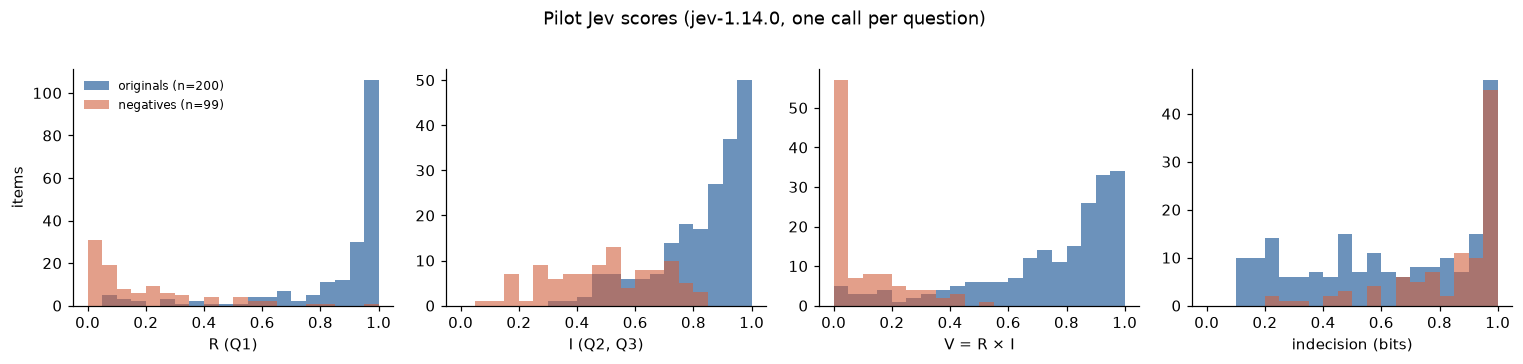

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
bins = np.linspace(0, 1, 21)
for ax, col, label in zip(axes, ["R", "I", "V", "indecision"], ["R (Q1)", "I (Q2, Q3)", "V = R × I", "indecision (bits)"]):
    ax.hist(orig[col], bins=bins, alpha=0.75, label=f"originals (n={len(orig)})", color="#3b6ea5")
    ax.hist(neg[col], bins=bins, alpha=0.6, label=f"negatives (n={len(neg)})", color="#d1603d")
    ax.set_xlabel(label)
axes[0].set_ylabel("items")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Pilot Jev scores (jev-1.14.0, one call per question)", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_jev_distributions.pdf", bbox_inches="tight")
plt.show()

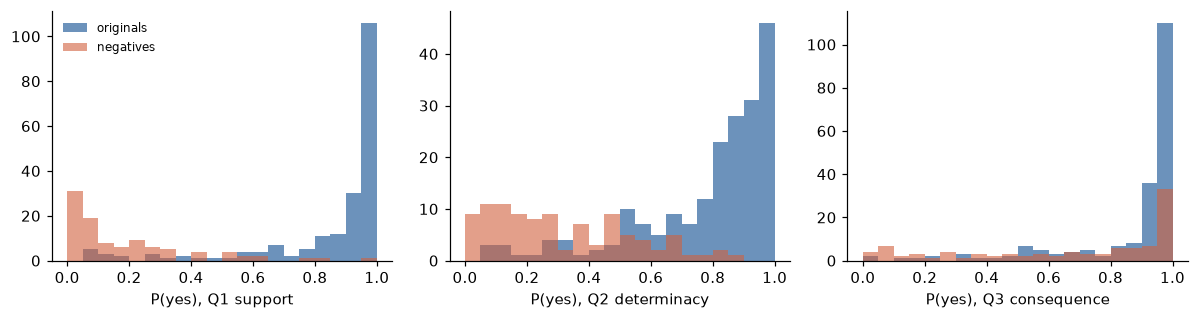

In [15]:
qcols = {}
for q in ["q1", "q2", "q3"]:
    qcols[q] = long[(long["battery"] == "orig") & (long["question"] == q)].set_index("item_id")["p_yes"]
qdf = pd.DataFrame(qcols).join(df.set_index("item_id")[["is_negative"]])
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, q, name in zip(axes, ["q1", "q2", "q3"], ["Q1 support", "Q2 determinacy", "Q3 consequence"]):
    ax.hist(qdf.loc[~qdf["is_negative"], q], bins=bins, alpha=0.75, color="#3b6ea5", label="originals")
    ax.hist(qdf.loc[qdf["is_negative"], q], bins=bins, alpha=0.6, color="#d1603d", label="negatives")
    ax.set_xlabel(f"P(yes), {name}")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_jev_questions.pdf", bbox_inches="tight")
plt.show()

**Findings.** On originals, R is concentrated near 1 (median 0.96), with a tail of low-R items: 10% are below 0.56. I is lower and more spread (median 0.88, IQR 0.74–0.95). Lookup items score higher than arithmetic items on both R and I, and FinQA arithmetic is the lowest stratum.

Negatives are pulled down strongly on Q1 and Q2, but much less on Q3.

For H2–H5, the useful property is that I has spread *within* R ≥ 0.9: the quintiles and cells need it. For H5, the low-R tail supplies the natural low-reliability items.

## 6. H1 and D1 preview: does R track correctness? (Spec 3, A1)

The evaluation set follows A1:

- **Positives:** originals that have a `#neg` copy, labelled 1.
- **Negatives:** their negatives, labelled 0.

The 95% intervals come from a **cluster bootstrap** (2,000 resamples) over base items, so each original stays with its negative. H1 requires an overall AUROC ≥ 0.70. **D1** fires if the AUROC on `arith` items is below 0.70.

In [16]:
def boot_auroc(frame, score, n=N_BOOT, label="R"):
    # frame: one row per pair with columns score (original) and score_neg
    pos, negs = frame[score].to_numpy(), frame[f"{score}_neg"].to_numpy()
    def auc(idx):
        y = np.r_[np.ones(len(idx)), np.zeros(len(idx))]
        return roc_auc_score(y, np.r_[pos[idx], negs[idx]])
    point = auc(np.arange(len(frame)))
    g = rng(SEED, "pilot_auroc", label, score, len(frame))
    reps = [auc(g.integers(0, len(frame), len(frame))) for _ in range(n)]
    lo, hi = np.percentile(reps, [2.5, 97.5])
    return point, lo, hi

a1 = []
for subset, frame in [("overall", pairs), ("lookup", pairs[pairs["answer_type"] == "lookup"]),
                      ("arith", pairs[pairs["answer_type"] == "arith"]),
                      ("finqa", pairs[pairs["dataset"] == "finqa"]), ("tatqa", pairs[pairs["dataset"] == "tatqa"])]:
    for score in ["R", "R_para", "I", "V"]:
        p, lo, hi = boot_auroc(frame, score, label=subset)
        a1.append({"subset": subset, "score": score, "pairs": len(frame), "AUROC": p, "CI low": lo, "CI high": hi})
a1 = pd.DataFrame(a1)
display(a1.pivot_table(index=["subset", "pairs"], columns="score", values="AUROC")[["R", "R_para", "I", "V"]])
display(a1[a1["score"].isin(["R", "R_para"])].set_index(["subset", "score"]))

,score,R,R_para,I,V
subset,pairs,,,,
arith,71,0.908,0.896,0.869,0.919
finqa,50,0.904,0.889,0.844,0.911
lookup,28,1.000,1.000,0.971,1.000
overall,99,0.948,0.940,0.906,0.955
tatqa,49,0.981,0.979,0.951,0.984


pairs  AUROC  CI low  CI high
subset  score                                
overall R          99  0.948   0.914    0.975
        R_para     99  0.940   0.904    0.970
lookup  R          28  1.000   1.000    1.000
        R_para     28  1.000   1.000    1.000
arith   R          71  0.908   0.853    0.952
        R_para     71  0.896   0.835    0.944
finqa   R          50  0.904   0.839    0.957
        R_para     50  0.889   0.820    0.947
tatqa   R          49  0.981   0.954    0.999
        R_para     49  0.979   0.947    1.000

**By perturbation type.** The negatives differ in how far the wrong answer is from the gold:

- **numeric factors:** 0.8 and 1.25 are subtle, 0.5 and 2 are coarse;
- **sign flips** on direction items;
- **span swaps** on lookup items.

Jev is expected to be weakest on subtle numeric errors. The protocol flags derivation checking as Jev's known weakness (Related work, third risk), and the subtle factors are closest to the "persuasive wrong answer" of E3's corrupted variant.

In [17]:
pairs["perturb"] = pairs["perturbation_neg"]
by_p = []
for kind, frame in pairs.groupby("perturb"):
    p, lo, hi = boot_auroc(frame, "R", label=f"perturb:{kind}")
    by_p.append({"perturbation": kind, "pairs": len(frame), "AUROC of R": p, "CI low": lo, "CI high": hi,
                 "median R original": frame["R"].median(), "median R negative": frame["R_neg"].median()})
display(pd.DataFrame(by_p).set_index("perturbation").sort_values("AUROC of R"))

,pairs,AUROC of R,CI low,CI high,median R original,median R negative
perturbation,,,,,,
sign_flip,16,0.871,0.736,0.973,0.975,0.270
factor:1.25,16,0.926,0.820,0.996,0.950,0.050
factor:0.8,12,0.934,0.767,1.000,0.975,0.220
factor:2,20,0.941,0.845,0.992,0.930,0.070
factor:0.5,21,1.000,1.000,1.000,0.950,0.080
span_swap,14,1.000,1.000,1.000,0.990,0.055


**Findings.** R separates originals from wrong answers far above the pre-registered 0.70: overall AUROC 0.95 [0.91, 0.97]. On arithmetic items it is 0.91 [0.85, 0.95], so the D1 preview is clear. Lookup pairs are separated perfectly, though there are only 28 of them (27 TAT-QA, 1 FinQA). The paraphrased Q1′ performs the same.

The errors Jev misses are the ones the protocol anticipated. Sign flips (AUROC 0.87) and the subtle factor 0.8 (median R of the negatives 0.22) are hardest; coarse factors and span swaps are trivial. These are FinQA-style derivation errors: AUROC is 0.91 on FinQA pairs (almost all arithmetic) versus 0.98 on TAT-QA pairs.

**For E3:** the "corrupted" variant should use subtle perturbations, or Jev will catch them too easily.

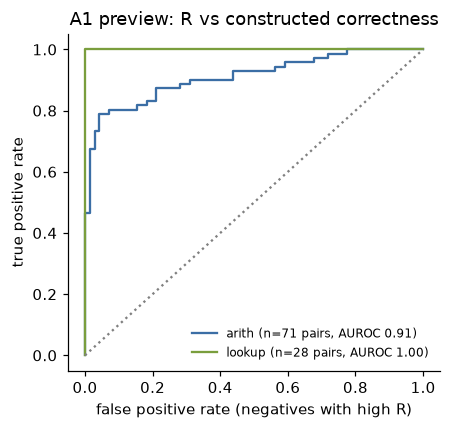

In [18]:
fig, ax = plt.subplots(figsize=(4.2, 4))
for frame, name, c in [(pairs[pairs["answer_type"] == "arith"], "arith", "#3b6ea5"),
                       (pairs[pairs["answer_type"] == "lookup"], "lookup", "#7a9e3d")]:
    y = np.r_[np.ones(len(frame)), np.zeros(len(frame))]
    s = np.r_[frame["R"], frame["R_neg"]]
    order = np.argsort(-s, kind="stable")
    tpr = np.r_[0, np.cumsum(y[order]) / y.sum()]
    fpr = np.r_[0, np.cumsum(1 - y[order]) / (1 - y).sum()]
    ax.plot(fpr, tpr, label=f"{name} (n={len(frame)} pairs, AUROC {roc_auc_score(y, s):.2f})", color=c)
ax.plot([0, 1], [0, 1], ls=":", color="grey")
ax.set_xlabel("false positive rate (negatives with high R)")
ax.set_ylabel("true positive rate")
ax.set_title("A1 preview: R vs constructed correctness")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_jev_roc.pdf", bbox_inches="tight")
plt.show()

## 7. Do only the support questions separate negatives? (construct separation)

Spec 1 regenerates each negative's Q3 check from its wrong answer, *"so that only Q1 should separate them from originals"*. Under the thesis, I is P(consequence | datum true): it should not drop just because the datum is false.

If Q2 and Q3 also fall sharply for negatives, I partly measures correctness, and the R/I decomposition is weaker than intended. That bears on D3 and on how H4 can be interpreted.

In [19]:
sep = []
pq = {}
for b_, sfx in (("orig", ""), ("para", "p")):
    for q in QUESTIONS:
        s = long[(long["battery"] == b_) & (long["question"] == q)].set_index("item_id")["p_yes"]
        pq[f"{q}{sfx}"] = s
pq = pd.DataFrame(pq)
po = pq.loc[pairs["item_id"]].to_numpy()
pn = pq.loc[pairs["item_id_neg"]].to_numpy()
for j, q in enumerate(pq.columns):
    diff = po[:, j] - pn[:, j]
    y = np.r_[np.ones(len(diff)), np.zeros(len(diff))]
    sep.append({"question": q, "median P(yes) original": np.median(po[:, j]), "median P(yes) negative": np.median(pn[:, j]),
                "mean paired drop": diff.mean(), "AUROC": roc_auc_score(y, np.r_[po[:, j], pn[:, j]]),
                "Wilcoxon p": stats.wilcoxon(diff).pvalue if np.any(diff) else 1.0})
display(pd.DataFrame(sep).set_index("question"))

,median P(yes) original,median P(yes) negative,mean paired drop,AUROC,Wilcoxon p
question,,,,,
q1,0.97,0.09,0.658,0.948,9.785e-17
q2,0.89,0.26,0.464,0.901,8.705e-17
q3,0.97,0.82,0.213,0.698,1.058e-09
q1p,0.97,0.13,0.617,0.940,7.560e-17
q2p,0.75,0.27,0.408,0.896,1.392e-16
q3p,0.97,0.81,0.217,0.721,6.111e-10


**Findings.** The expectation that only Q1 separates negatives holds for Q3 but **not for Q2**:

- **Q1 (support):** AUROC 0.95, as intended.
- **Q2 (determinacy):** P(yes) falls from 0.89 to 0.26 on wrong answers, with AUROC 0.90. Jev reads "does the context determine *this* answer uniquely?" as largely "is this answer right?".
- **Q3 (consequence):** falls only modestly, from 0.97 to 0.82 (AUROC 0.70). Since each negative's check is derived from its own wrong answer, this is close to what the thesis wants: P(consequence | datum assumed true).

**Implication.** I = mean(Q2, Q3) inherits a correctness component from Q2. This is a construct-validity issue for the R/I decomposition, and it sharpens H1's question of whether I captures something new. Options to weigh before the full run, an owner decision:

- keep I as pre-registered and report Q2 and Q3 separately as a robustness analysis;
- revise Q2's wording, which Spec 1's freeze rule treats as a battery change: bump `battery_version` and re-score;
- or residualise Q2 on R.

## 8. D3 preview: are R and I separable? (Spec 3, A2)

D3 fires, halting before E1, if |ρ(R, I)| ≥ 0.8 on pool originals. Spearman correlations come with Fisher-z 95% intervals, as in Spec 3.

The table also shows two further correlations:
- the internal consistency of I (Q2 with Q3);
- the same R–I correlation on originals plus negatives. This is **not** the gate quantity, but it shows how negatives couple the two scores.

In [20]:
def spearman_ci(x, y):
    r, p = stats.spearmanr(x, y)
    n = len(x)
    z, se = np.arctanh(r), 1 / math.sqrt(n - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se), p, n

corr_rows = []
oq = pq.loc[orig["item_id"]]
for name, x, y in [
    ("ρ(R, I) — D3 quantity, originals", orig["R"], orig["I"]),
    ("ρ(R, I) — FinQA originals", orig.loc[orig["dataset"] == "finqa", "R"], orig.loc[orig["dataset"] == "finqa", "I"]),
    ("ρ(R, I) — TAT-QA originals", orig.loc[orig["dataset"] == "tatqa", "R"], orig.loc[orig["dataset"] == "tatqa", "I"]),
    ("ρ(R′, I′) — paraphrase, originals", orig["R_para"], orig["I_para"]),
    ("ρ(Q2, Q3) — internal consistency of I", oq["q2"], oq["q3"]),
    ("ρ(Q1, Q2), originals", oq["q1"], oq["q2"]),
    ("ρ(Q1, Q3), originals", oq["q1"], oq["q3"]),
    ("ρ(R, I) — originals + negatives (not the gate)", df["R"], df["I"]),
]:
    r, lo, hi, p, n = spearman_ci(x, y)
    corr_rows.append({"correlation": name, "n": n, "ρ": r, "CI low": lo, "CI high": hi, "p": p})
corr = pd.DataFrame(corr_rows).set_index("correlation")
display(corr)

,n,ρ,CI low,CI high,p
correlation,,,,,
"ρ(R, I) — D3 quantity, originals",200,0.726,0.653,0.785,5.644e-34
"ρ(R, I) — FinQA originals",100,0.762,0.665,0.833,3.530e-20
"ρ(R, I) — TAT-QA originals",100,0.598,0.454,0.711,5.284e-11
"ρ(R′, I′) — paraphrase, originals",200,0.722,0.648,0.782,1.749e-33
"ρ(Q2, Q3) — internal consistency of I",200,0.179,0.041,0.310,1.126e-02
"ρ(Q1, Q2), originals",200,0.874,0.836,0.903,6.708e-64
"ρ(Q1, Q3), originals",200,0.217,0.081,0.346,2.000e-03
"ρ(R, I) — originals + negatives (not the gate)",299,0.827,0.788,0.860,2.566e-76


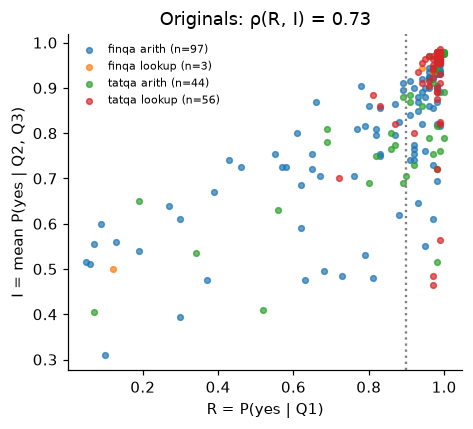

In [21]:
fig, ax = plt.subplots(figsize=(4.4, 4))
for (ds, at), g in orig.groupby(["dataset", "answer_type"]):
    ax.scatter(g["R"], g["I"], s=14, alpha=0.7, label=f"{ds} {at} (n={len(g)})")
ax.axvline(0.9, ls=":", color="grey")
ax.set_xlabel("R = P(yes | Q1)")
ax.set_ylabel("I = mean P(yes | Q2, Q3)")
ax.set_title(f"Originals: ρ(R, I) = {corr.iloc[0]['ρ']:.2f}")
ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_jev_R_vs_I.pdf", bbox_inches="tight")
plt.show()

**Findings.** On originals, ρ(R, I) = 0.73 [0.65, 0.79]. That is below D3's 0.8, so the gate would not fire on this estimate, but the interval's upper end touches the threshold. The overall figure hides a dataset difference: FinQA is 0.76 [0.67, 0.83], with an interval that crosses 0.8, while TAT-QA is 0.60. Adding negatives raises the coupling to 0.83.

The source is visible in the question-level correlations:
- Q1–Q2: 0.87;
- Q1–Q3: 0.22;
- Q2–Q3: 0.18, so the two components of I barely agree with each other.

**For the paper and the full run:**
- D3 is a live risk, not a formality.
- I is effectively two different signals: a determinacy signal that tracks support, and a consequence signal that does not.
- Spec 3 should report the Q2 and Q3 components alongside I.

## 9. Robustness to paraphrase (E0, test-retest between batteries)

The protocol scores a paraphrased battery on the full pool to test whether R and I depend on wording. The checks below compare each construct with its paraphrased counterpart: rank agreement, mean shift, and agreement on the R ≥ 0.9 filter.

In [22]:
para = []
for a, b_ in [("R", "R_para"), ("I", "I_para"), ("V", "V_para"), ("indecision", "indecision_para")]:
    r, lo, hi, p, n = spearman_ci(orig[a], orig[b_])
    para.append({"construct": a, "ρ(orig, para)": r, "CI low": lo, "CI high": hi,
                 "mean (para − orig)": (orig[b_] - orig[a]).mean(),
                 "mean |para − orig|": (orig[b_] - orig[a]).abs().mean()})
display(pd.DataFrame(para).set_index("construct"))
agree = ((orig["R"] >= 0.9) == (orig["R_para"] >= 0.9)).mean()
kappa_tbl = pd.crosstab(orig["R"] >= 0.9, orig["R_para"] >= 0.9, rownames=["R ≥ 0.9"], colnames=["R′ ≥ 0.9"])
display(kappa_tbl)
po_ = agree
pe = ((orig["R"] >= 0.9).mean() * (orig["R_para"] >= 0.9).mean()
      + (orig["R"] < 0.9).mean() * (orig["R_para"] < 0.9).mean())
print(f"agreement on the R ≥ 0.9 filter: {agree:.1%}; Cohen's κ = {(po_ - pe) / (1 - pe):.2f}")

,"ρ(orig, para)",CI low,CI high,mean (para − orig),mean |para − orig|
construct,,,,,
R,0.945,0.927,0.958,-0.005,0.019
I,0.963,0.951,0.972,-0.045,0.050
V,0.972,0.963,0.979,-0.045,0.051
indecision,0.888,0.855,0.914,0.135,0.150


R′ ≥ 0.9,False,True
R ≥ 0.9,,
False,60,4
True,7,129


agreement on the R ≥ 0.9 filter: 94.5%; Cohen's κ = 0.88


**Findings.** Paraphrasing the battery barely changes the rankings: ρ = 0.95 for R and 0.96 for I. The R ≥ 0.9 filter agrees on 94.5% of items (κ = 0.88).

Levels shift slightly. I′ is 0.05 lower on average, mostly because Q2′ answers "yes" less often than Q2 (median 0.75 vs 0.89). Indecision is the least stable quantity (ρ 0.89). Conclusions based on ranks and thresholds should transfer across wordings.

## 10. D4 projection: will the I × S cells be large enough?

The I × S cells (E1-C) and the I quintiles (E2) are drawn from items with R ≥ 0.9. D4 fires if any dataset × cell has fewer than 100 items; the response is to relax the threshold to 0.8, and then to drop the filter.

S is not measured yet, so this section shows the share of originals passing each R threshold. It projects cell sizes onto the full pool assuming median splits give four roughly equal cells. That assumption holds only if I and S are roughly independent; a strong I–S correlation would shrink two of the cells. The projection is an upper-bound sanity check, not the D4 count.

In [23]:
full_by_ds = {ds: sum(v["pool_composition"].values()) for ds, v in split_manifest["datasets"].items()}
d4 = []
for ds, g in orig.groupby("dataset"):
    for thr in (0.9, 0.8):
        share = (g["R"] >= thr).mean()
        k = int((g["R"] >= thr).sum())
        lo, hi = stats.binomtest(k, len(g)).proportion_ci(method="wilson")
        d4.append({"dataset": ds, "R threshold": thr, "pilot share": share, "95% CI": f"[{lo:.2f}, {hi:.2f}]",
                   "full pool items": full_by_ds[ds], "projected eligible": int(share * full_by_ds[ds]),
                   "projected per cell (÷4)": int(share * full_by_ds[ds] / 4),
                   "projected, lower CI ÷4": int(lo * full_by_ds[ds] / 4)})
display(pd.DataFrame(d4).set_index(["dataset", "R threshold"]))
display(orig.assign(R90=orig["R"] >= 0.9).groupby(["dataset", "answer_type"])["R90"].agg(["mean", "size"])
        .rename(columns={"mean": "share R ≥ 0.9", "size": "n"}))

pilot share        95% CI  full pool items  \
dataset R threshold                                               
finqa   0.9                 0.54  [0.44, 0.63]             6145   
        0.8                 0.67  [0.57, 0.75]             6145   
tatqa   0.9                 0.82  [0.73, 0.88]            13124   
        0.8                 0.92  [0.85, 0.96]            13124   

                     projected eligible  projected per cell (÷4)  \
dataset R threshold                                                
finqa   0.9                        3318                      829   
        0.8                        4117                     1029   
tatqa   0.9                       10761                     2690   
        0.8                       12074                     3018   

                     projected, lower CI ÷4  
dataset R threshold                          
finqa   0.9                             680  
        0.8                             880  
tatqa   0.9                            2406  
        0.8                            2788

share R ≥ 0.9   n
dataset answer_type                   
finqa   arith                0.536  97
        lookup               0.667   3
tatqa   arith                0.682  44
        lookup               0.929  56

**Findings.** 54% of FinQA and 82% of TAT-QA originals pass R ≥ 0.9. Even at the lower confidence bound and with four equal cells, that projects to about 680 FinQA and 2,400 TAT-QA items per cell, far above D4's minimum of 100. D4 is unlikely to fire unless I and S turn out to be very strongly correlated.

FinQA arithmetic has the lowest pass rate (54%). The reliability filter will therefore shift the eligible pool toward TAT-QA and lookup items. Spec 5's dataset fixed effects and per-dataset medians are there for this reason.

## 11. What drives I? (D2 stand-in and check provenance)

D2 asks whether I is just a difficulty proxy: it fires if ρ(I, base-model accuracy) ≥ 0.7. Base-model accuracy comes from Spec 2 (OLMo 3 7B Instruct, milestone 4), so D2 cannot be previewed yet.

Two weaker diagnostics are available now:
- I's association with surface difficulty (answer type, context length);
- whether I depends on how the Q3 check was generated (template or LLM). A strong source effect would mean Q3 partly measures the check generator rather than the item.

In [24]:
diag = []
for name, x in [("question + context tokens", orig["qa_tokens"]), ("context characters", orig["context_chars"])]:
    for col in ("I", "R"):
        r, lo, hi, p, n = spearman_ci(orig[col], x)
        diag.append({"feature": name, "score": col, "ρ": r, "CI low": lo, "CI high": hi, "n": n})
display(pd.DataFrame(diag).set_index(["feature", "score"]))
oq3 = orig.merge(pq[["q2", "q3"]], left_on="item_id", right_index=True)
display(oq3.groupby(["answer_type", "source"])[["q2", "q3", "I"]].median().assign(
    n=oq3.groupby(["answer_type", "source"]).size()))
arith_o = oq3[oq3["answer_type"] == "arith"]
if arith_o["source"].value_counts().min() >= 10:
    u = stats.mannwhitneyu(arith_o.loc[arith_o["source"] == "template", "q3"], arith_o.loc[arith_o["source"] != "template", "q3"])
    print(f"Q3 by check source within arith originals: Mann–Whitney p = {u.pvalue:.3g}")
else:
    print("check source is confounded with answer type (arith: templates; lookup: LLM); no within-type test is possible")
display(oq3.groupby("check_type")["q3"].agg(["median", "mean", "size"]))

ρ  CI low  CI high    n
feature                   score                             
question + context tokens I     -0.251  -0.376   -0.116  200
                          R     -0.265  -0.389   -0.131  200
context characters        I     -0.275  -0.398   -0.141  200
                          R     -0.285  -0.407   -0.152  200

q2    q3      I    n
answer_type source                           
arith       llm       0.795  0.97  0.882    2
            template  0.800  0.96  0.815  139
lookup      llm       0.960  0.96  0.955   56
            template  0.890  0.98  0.935    3

check source is confounded with answer type (arith: templates; lookup: LLM); no within-type test is possible


,median,mean,size
check_type,,,
direction,0.97,0.934,44
magnitude,0.94,0.809,10
ordering,0.96,0.840,123
total,0.97,0.933,23


**Findings.**
- **Item length.** Both I and R fall slightly with item length (ρ ≈ −0.25 to −0.29), so longer items are judged less supported and less determinate. This weak association is far from the D2 threshold of 0.7. Whether I tracks *model* difficulty can only be answered with base-model accuracy (Spec 2).
- **Check source.** The source of the Q3 check is confounded with answer type: arithmetic checks are almost all templates (139 of 141) and lookup checks almost all LLM-written (56 of 59). So the pilot cannot tell a generator effect from an answer-type effect.
- **Check type.** Median Q3 is similar across check types. Magnitude and ordering checks have a lower mean, with more items where Jev doubts the consequence.

## 12. Indecision

Indecision is the maximum binary entropy across Q1–Q3. It flags items on which Jev is unsure of at least one question.

The protocol lists it as a construct. In the analyses it serves as a covariate and a diagnostic, not a selection score.

In [25]:
which = pq.loc[orig["item_id"], ["q1", "q2", "q3"]].apply(lambda r: (-(r * np.log2(r.clip(1e-12)) + (1 - r) * np.log2((1 - r).clip(1e-12)))).idxmax(), axis=1)
print("question that sets the indecision maximum (originals):")
display(which.value_counts().rename("items").to_frame())
r, lo, hi, p, n = spearman_ci(orig["indecision"], orig["R"])
print(f"ρ(indecision, R) = {r:.2f} [{lo:.2f}, {hi:.2f}];  share of originals with indecision > 0.9 bits: "
      f"{(orig['indecision'] > 0.9).mean():.1%}")

question that sets the indecision maximum (originals):


,items
q2,133
q3,47
q1,20


ρ(indecision, R) = -0.67 [-0.74, -0.59];  share of originals with indecision > 0.9 bits: 31.0%


**Findings.** Indecision is set by Q2 for 133 of 200 originals: Jev is least certain about determinacy. It correlates −0.67 with R, so uncertain items tend to be less supported. Thirty-one percent of originals have at least one near-coin-flip answer (> 0.9 bits).

Indecision is therefore largely a by-product of Q2 and should be read alongside the Q2 issue in §7–8.

## 13. Summary: what the pilot says about the protocol

The table assembles the pilot quantities next to the pre-registered thresholds. *Preview* means the same quantity Spec 3 will compute on the full pool, here on the pilot with its interval. Nothing here is a gate decision.

In [26]:
def a1_row(subset, score="R"):
    r = a1[(a1["subset"] == subset) & (a1["score"] == score)].iloc[0]
    return r["AUROC"], r["CI low"], r["CI high"], int(r["pairs"])

auc_all, auc_all_lo, auc_all_hi, n_all = a1_row("overall")
auc_ar, auc_ar_lo, auc_ar_hi, n_ar = a1_row("arith")
auc_lk, auc_lk_lo, auc_lk_hi, n_lk = a1_row("lookup")
rRI = corr.loc["ρ(R, I) — D3 quantity, originals"]
share90 = (orig["R"] >= 0.9).mean()
summary = pd.DataFrame([
    ["H1 / A1", "AUROC of R, overall", "≥ 0.70 supports H1", f"{auc_all:.3f} [{auc_all_lo:.3f}, {auc_all_hi:.3f}], {n_all} pairs",
     "preview: well above threshold"],
    ["D1", "AUROC of R, arith", "< 0.70 fires", f"{auc_ar:.3f} [{auc_ar_lo:.3f}, {auc_ar_hi:.3f}], {n_ar} pairs",
     "preview: " + ("would not fire" if auc_ar_lo >= 0.70 else "interval reaches the threshold")],
    ["A1 (lookup)", "AUROC of R, lookup", "reported", f"{auc_lk:.3f} [{auc_lk_lo:.3f}, {auc_lk_hi:.3f}], {n_lk} pairs", "preview"],
    ["D2", "ρ(I, base-model accuracy)", "≥ 0.7 fires", "needs Spec 2 (M4)", "not yet"],
    ["D3", "|ρ(R, I)|, originals", "≥ 0.8 fires", f"{rRI['ρ']:.3f} [{rRI['CI low']:.3f}, {rRI['CI high']:.3f}], n={int(rRI['n'])}",
     "preview: below threshold, upper CI " + f"{rRI['CI high']:.2f}" + "; FinQA CI crosses 0.8 — at risk"],
    ["Construct separation", "AUROC on negatives: Q1 / Q2 / Q3", "only Q1 should separate (Spec 1)",
     " / ".join(f"{x:.2f}" for x in pd.DataFrame(sep).set_index("question").loc[["q1", "q2", "q3"], "AUROC"]),
     "Q2 also separates: I carries a correctness component"],
    ["D4", "smallest dataset × cell (R ≥ 0.9)", "< 100 fires", f"share R ≥ 0.9: {share90:.1%} of originals; see §10", "projection only (needs S)"],
    ["E0 test-retest", "ρ(R, R′), ρ(I, I′)", "reported",
     f"{stats.spearmanr(orig['R'], orig['R_para'])[0]:.3f}, {stats.spearmanr(orig['I'], orig['I_para'])[0]:.3f}", "preview"],
    ["Spec 1 determinism", "mean |ΔP|, repeat", f"> {manifest['determinism']['tolerance']} → triplicate",
     f"{manifest['determinism']['mean_abs_diff']:.4f}",
     "fired: triplicate scoring" if manifest["determinism"]["triplicate"] else "passed: single scoring"],
    ["Spec 1 batching", "mean |batched − single|", f"≤ {manifest['batching']['allowed']:.4f}",
     f"{manifest['batching']['mean_abs_diff_batched_vs_single']:.4f}", "passed: batched mode"],
    ["H2–H6", "—", "—", "need S, G, C", "not addressed"],
], columns=["element", "quantity", "pre-registered rule", "pilot value [95% CI]", "status"]).set_index("element")
display(summary)

,quantity,pre-registered rule,pilot value [95% CI],status
element,,,,
H1 / A1,"AUROC of R, overall",≥ 0.70 supports H1,"0.948 [0.914, 0.975], 99 pairs",preview: well above threshold
D1,"AUROC of R, arith",< 0.70 fires,"0.908 [0.853, 0.952], 71 pairs",preview: would not fire
A1 (lookup),"AUROC of R, lookup",reported,"1.000 [1.000, 1.000], 28 pairs",preview
D2,"ρ(I, base-model accuracy)",≥ 0.7 fires,needs Spec 2 (M4),not yet
D3,"|ρ(R, I)|, originals",≥ 0.8 fires,"0.726 [0.653, 0.785], n=200","preview: below threshold, upper CI 0.79; FinQA..."
Construct separation,AUROC on negatives: Q1 / Q2 / Q3,only Q1 should separate (Spec 1),0.95 / 0.90 / 0.70,Q2 also separates: I carries a correctness com...
D4,smallest dataset × cell (R ≥ 0.9),< 100 fires,share R ≥ 0.9: 68.0% of originals; see §10,projection only (needs S)
E0 test-retest,"ρ(R, R′), ρ(I, I′)",reported,"0.945, 0.963",preview
Spec 1 determinism,"mean |ΔP|, repeat",> 0.017 → triplicate,0.0161,passed: single scoring


### Paper text

The cell below prints methods and results sentences with the numbers filled in from this notebook, so the text and the numbers cannot drift apart. They describe the pilot. In the paper the pilot belongs in the methods (measurement decisions) or an appendix. The confirmatory E0 numbers come from the full run.

In [27]:
sep_df = pd.DataFrame(sep).set_index("question")
q2_auc, q3_auc = sep_df.loc["q2", "AUROC"], sep_df.loc["q3", "AUROC"]
r_rr = stats.spearmanr(orig["R"], orig["R_para"])[0]
r_ii = stats.spearmanr(orig["I"], orig["I_para"])[0]
text = f'''
METHODS — Jev scoring.
We score every item with TypeSafe's Jev (System One API), pinned to the versioned model jev-1.14.0; every
response reported this version. Each item's context, question and stated answer form one state, and all six
yes/no ("noul") questions, the battery and its paraphrase, are sent in a single request. Jev returns P(yes)
rounded to 0.01. On a 200-item pilot, repeating identical requests changed P(yes) by
{manifest['determinism']['mean_abs_diff']:.3f} on average, within our tolerance of {manifest['determinism']['tolerance']}
(chosen after the pilot; the initial value was 0.01), so each item is scored once; above the tolerance,
every item would be scored three times and the mean used. Single calls are highly reliable
(ICC(1) = {rel['ICC(1), one call'].loc[['q1','q2','q3']].min():.2f}–{rel['ICC(1), one call'].loc[['q1','q2','q3']].max():.2f}
across Q1–Q3, from three repeats of all 299 items). Batched and single-question requests differed by {manifest['batching']['mean_abs_diff_batched_vs_single']:.3f}
(allowed: {manifest['batching']['allowed']:.3f}), so questions sent together do not influence each other
measurably, and batching cuts input tokens by {save:.0%}.

RESULTS — pilot (200 originals, {len(pairs)} constructed negatives).
R separates originals from negatives with wrong answers at AUROC {auc_all:.2f} (95% CI {auc_all_lo:.2f}–{auc_all_hi:.2f};
arithmetic {auc_ar:.2f}, lookup {auc_lk:.2f}), against the pre-registered 0.70; sign flips and small
multiplicative errors are the hardest to detect. R and I correlate at ρ = {rRI['ρ']:.2f}
(95% CI {rRI['CI low']:.2f}–{rRI['CI high']:.2f}), below the pre-registered separability threshold of 0.8 but
close to it. The coupling comes from the determinacy question: Q2 correlates {corr.loc['ρ(Q1, Q2), originals', 'ρ']:.2f}
with the support question and separates wrong answers almost as well (AUROC {q2_auc:.2f}), whereas the
consequence question is nearly independent of support (ρ = {corr.loc['ρ(Q1, Q3), originals', 'ρ']:.2f}) and
responds much less to wrong answers (AUROC {q3_auc:.2f}). Scores are robust to paraphrasing the battery
(ρ = {r_rr:.2f} for R, {r_ii:.2f} for I). {share90:.0%} of originals have R ≥ 0.9.
'''
print(text)


METHODS — Jev scoring.
We score every item with TypeSafe's Jev (System One API), pinned to the versioned model jev-1.14.0; every
response reported this version. Each item's context, question and stated answer form one state, and all six
yes/no ("noul") questions, the battery and its paraphrase, are sent in a single request. Jev returns P(yes)
rounded to 0.01. On a 200-item pilot, repeating identical requests changed P(yes) by
0.016 on average, within our tolerance of 0.017
(chosen after the pilot; the initial value was 0.01), so each item is scored once; above the tolerance,
every item would be scored three times and the mean used. Single calls are highly reliable
(ICC(1) = 0.99–1.00
across Q1–Q3, from three repeats of all 299 items). Batched and single-question requests differed by 0.015
(allowed: 0.026), so questions sent together do not influence each other
measurably, and batching cuts input tokens by 81%.

RESULTS — pilot (200 originals, 99 constructed negatives).
R separates ori

## 14. Limitations of the pilot, and what to carry into the full run

1. **Size.** There are 99 pairs for A1 and 200 originals for correlations, so intervals are wide. In particular the FinQA `lookup` stratum (3 originals) and individual perturbation types (13–21 pairs) are too small to read on their own.
2. **Constructed negatives only.** Every original verifies, so A1 measures detection of *constructed* wrong answers, not natural label noise. Coarse perturbations (factor 0.5 or 2, span swaps) are easier than natural errors; the subtle factors (0.8, 1.25) are the closest stand-in for persuasive wrong answers.
3. **Unvalidated Q3 checks.** Q3, Q3′, I and I′ are provisional until the annotators' labels are imported. If the check generator fails validation (under 90% acceptance), Q3 must be regenerated and re-scored. R is unaffected.
4. **Rounded probabilities.** Jev reports P(yes) to 0.01. Triplicate averaging gives a finer grid, but ties and ceiling effects at 0.99–1.00 remain, especially for R. This matters for the R ≥ 0.9 filter and for rank-based statistics.
5. **Model version.** All scores use `jev-1.14.0`. The aliases `jev-latest` and `jev-preview` resolved to this version on 24 October 2026, but they will move. The full run must use the same pinned version, and the paper should name it.
6. **Q2 coupling (owner decision).** Q2 behaves largely as a second support question (§7–8). Decide before the full run: keep the pre-registered I and add Q2/Q3-separate robustness analyses, or revise Q2. Revising is a battery change under Spec 1's freeze rule: bump `battery_version` and re-score.
7. **Pilot-informed tolerance.** The determinism tolerance was raised from 0.01 to 0.017 after the pilot showed a repeat difference of 0.016. This must be disclosed in the paper. The pilot's single-call scores and the triplicate means are both available, so robustness to the choice can be reported.
8. **Re-check in the full run.** The determinism and batching checks are repeated on the full run's own 200-item sample, as Spec 1 requires. The pilot's outcome (single scoring under 0.017, batched) is the expected outcome, not a substitute. If the full run's repeat difference exceeds 0.017, triplicate scoring applies.